<a href="https://colab.research.google.com/github/aniruddhtomar1530-arch/Car_Evolution/blob/main/Car_Evolution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import files
uploaded = files.upload()

import zipfile
import os

zip_file_name = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file_name, 'r') as zip_ref:
    zip_ref.extractall("data")

print("Files in dataset folder:", os.listdir("data"))
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Saving car+evaluation.zip to car+evaluation.zip
Files in dataset folder: ['car.names', 'car.data', 'car.c45-names']


In [ ]:
columns = ["buying","maint","doors","persons","lug_boot","safety","class"]

df = pd.read_csv("data/car.data", names=columns)

print("\nDataset Preview:")
print(df.head())
print(df.info())
print(df.describe())


Dataset Preview:
  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB
None
       buying  maint doors persons lug_boot safety  class
count    1728   1728  1728    1728     1728   1728   1728
unique      4      4     4       3        3      3    

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in df.columns:
    df[col] = le.fit_transform(df[col])

from sklearn.model_selection import train_test_split

X = df.drop("class", axis=1)
y = df["class"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

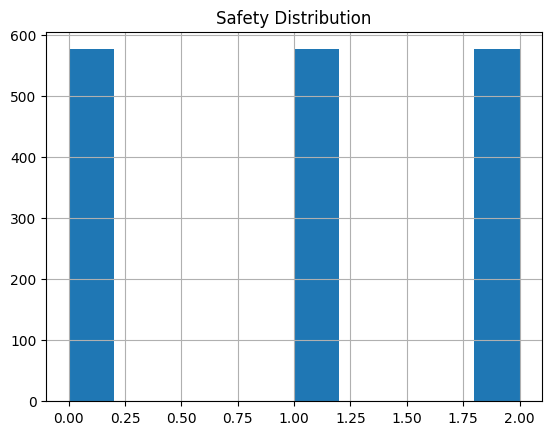

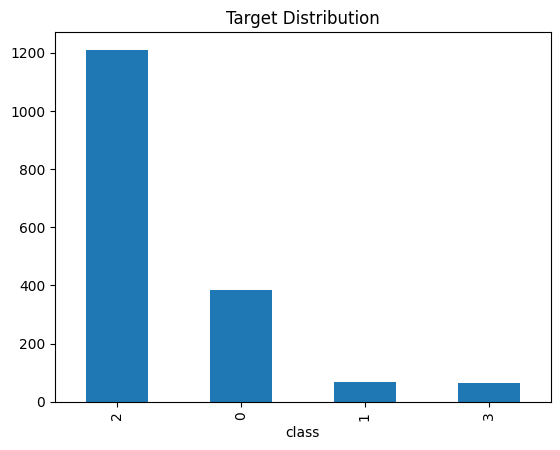

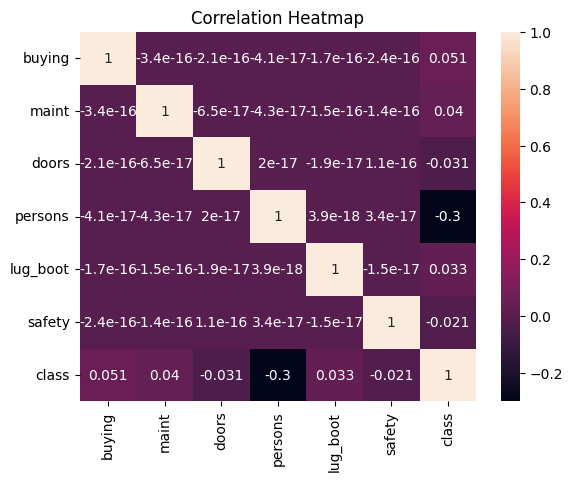

In [ ]:

# Histogram
plt.figure()
df['safety'].hist()
plt.title("Safety Distribution")
plt.show()

# Count Plot
plt.figure()
df['class'].value_counts().plot(kind='bar')
plt.title("Target Distribution")
plt.show()

# Heatmap
plt.figure()
sns.heatmap(df.corr(), annot=True)
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

rf = RandomForestClassifier()
dt = DecisionTreeClassifier()
knn = KNeighborsClassifier()

rf.fit(X_train, y_train)
dt.fit(X_train, y_train)
knn.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
dt_pred = dt.predict(X_test)
knn_pred = knn.predict(X_test)



Accuracy Scores:
Random Forest: 0.9624277456647399
Decision Tree: 0.9797687861271677
KNN: 0.9219653179190751


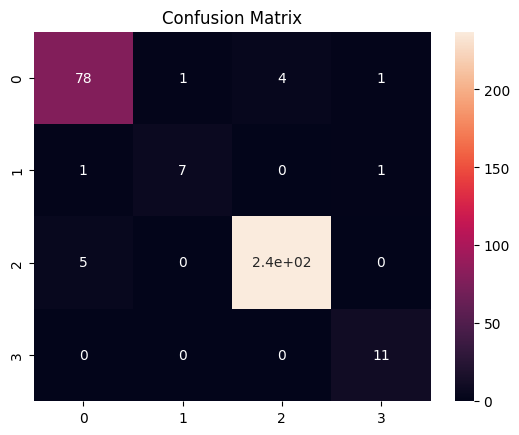

In [ ]:
from sklearn.metrics import accuracy_score

print("\nAccuracy Scores:")
print("Random Forest:", accuracy_score(y_test, rf_pred))
print("Decision Tree:", accuracy_score(y_test, dt_pred))
print("KNN:", accuracy_score(y_test, knn_pred))


from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, rf_pred)

plt.figure()
sns.heatmap(cm, annot=True)
plt.title("Confusion Matrix")
plt.show()

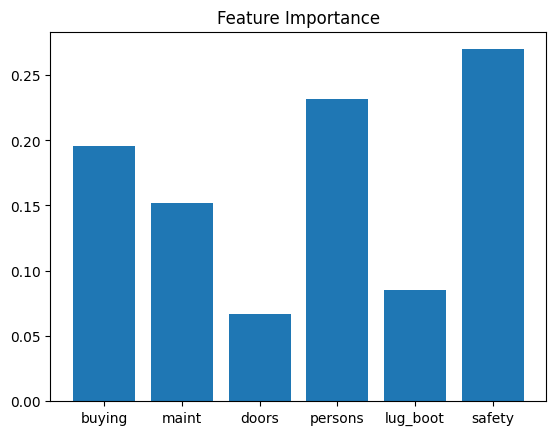


Sample Predictions:
Actual: [2 0 2 2 2 3 2 2 2 2]
Predicted: [2 2 2 2 2 3 2 2 2 2]


In [ ]:
importance = rf.feature_importances_

plt.figure()
plt.bar(X.columns, importance)
plt.title("Feature Importance")
plt.show()

print("\nSample Predictions:")
print("Actual:", y_test[:10].values)
print("Predicted:", rf_pred[:10])

Top 10 Feature Importances:
    Feature  Importance
5    safety    0.269817
3   persons    0.231246
0    buying    0.195194
1     maint    0.151880
4  lug_boot    0.085221
2     doors    0.066642


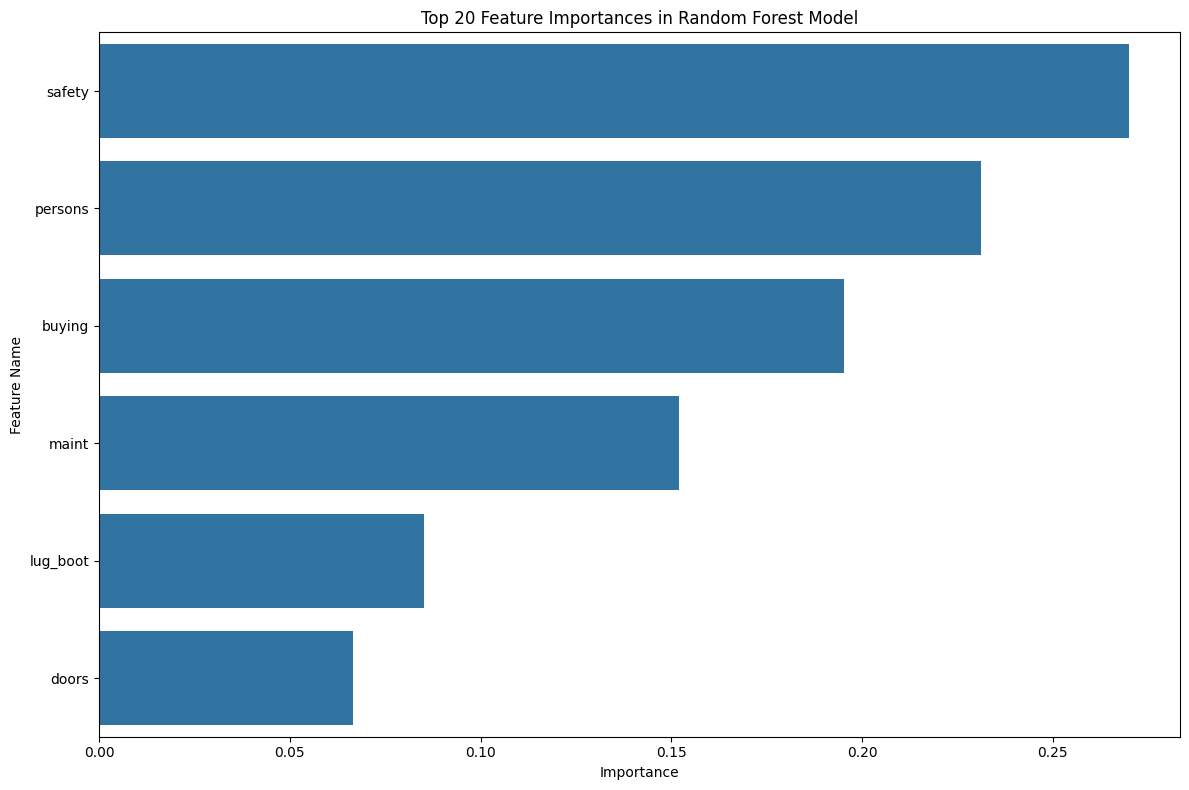

In [ ]:

importances = rf.feature_importances_

feature_names = X.columns

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

print("Top 10 Feature Importances:")
print(feature_importance_df.head(10))

plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(20))
plt.title('Top 20 Feature Importances in Random Forest Model')
plt.xlabel('Importance')
plt.ylabel('Feature Name')
plt.tight_layout()
plt.show()

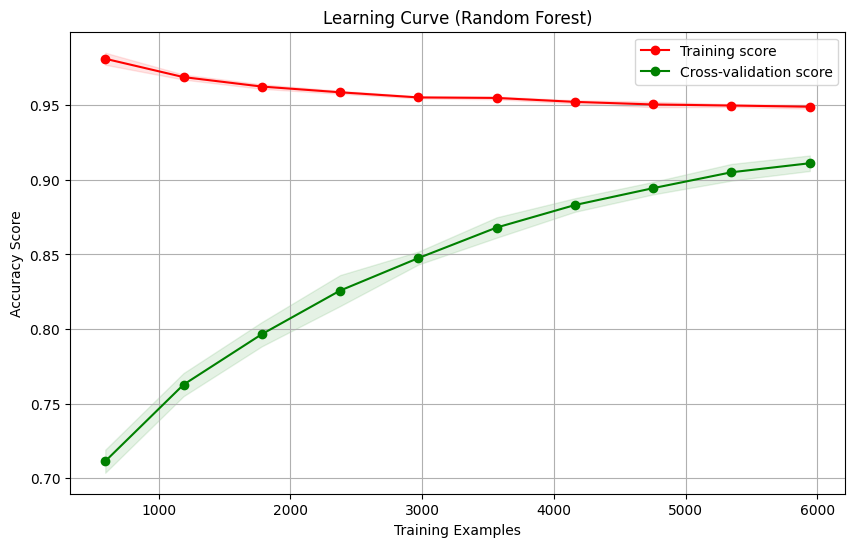

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier


df = pd.read_excel('/content/drive/MyDrive/Copy of Influenza_surveillance_Data.xlsx')

X = df.drop('Pathogen Test Result', axis=1)
y = df['Pathogen Test Result']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf = RandomForestClassifier(random_state=42)

param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False],
    'max_features': ['sqrt', 'log2']
}

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=20,
    cv=5,
    verbose=0,
    random_state=42,
    n_jobs=-1,
    scoring='accuracy'
)

random_search.fit(X_train, y_train)

best_model = random_search.best_estimator_

rf_model = best_model

train_sizes, train_scores, test_scores = learning_curve(
    rf_model, X, y, cv=5, n_jobs=-1,
    train_sizes=np.linspace(.1, 1.0, 10), scoring='accuracy'
)

train_scores_mean = np.mean(train_scores, axis=1)
train_scores_std = np.std(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)
test_scores_std = np.std(test_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.title('Learning Curve (Random Forest)')
plt.xlabel('Training Examples')
plt.ylabel('Accuracy Score')
plt.grid()

plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                 train_scores_mean + train_scores_std, alpha=0.1, color='r')
plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                 test_scores_mean + test_scores_std, alpha=0.1, color='g')
plt.plot(train_sizes, train_scores_mean, 'o-', color='r', label='Training score')
plt.plot(train_sizes, test_scores_mean, 'o-', color='g', label='Cross-validation score')

plt.legend(loc='best')
plt.show()